In [4]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from google.colab import files
from os import name

In [5]:
uploaded = files.upload()
uploaded_names = list(uploaded.keys())

def find_uploaded_image(keyword, fallback_index):
  matches = [
      name for name in uploaded_names if keyword.lower() in name.lower()
  ]

  if matches:
    return '/content/' + matches[0]

  if fallback_index < len(uploaded_names):
    return '/content/' + uploaded_names[fallback_index]
  raise ValueError(f"No Image Found For Keyword: {keyword}")

old_coins_path = find_uploaded_image('old-iranian-coins', 0)
money_path = find_uploaded_image('money', 1)
iranian_coin_path = find_uploaded_image('iranian-coin', 2)

print(old_coins_path)
print(money_path)
print(iranian_coin_path)

Saving iranian-coin.jpg to iranian-coin (1).jpg
Saving money.jpg to money (1).jpg
Saving old-iranian-coins.jpg to old-iranian-coins (1).jpg
/content/old-iranian-coins (1).jpg
/content/money (1).jpg
/content/iranian-coin (1).jpg


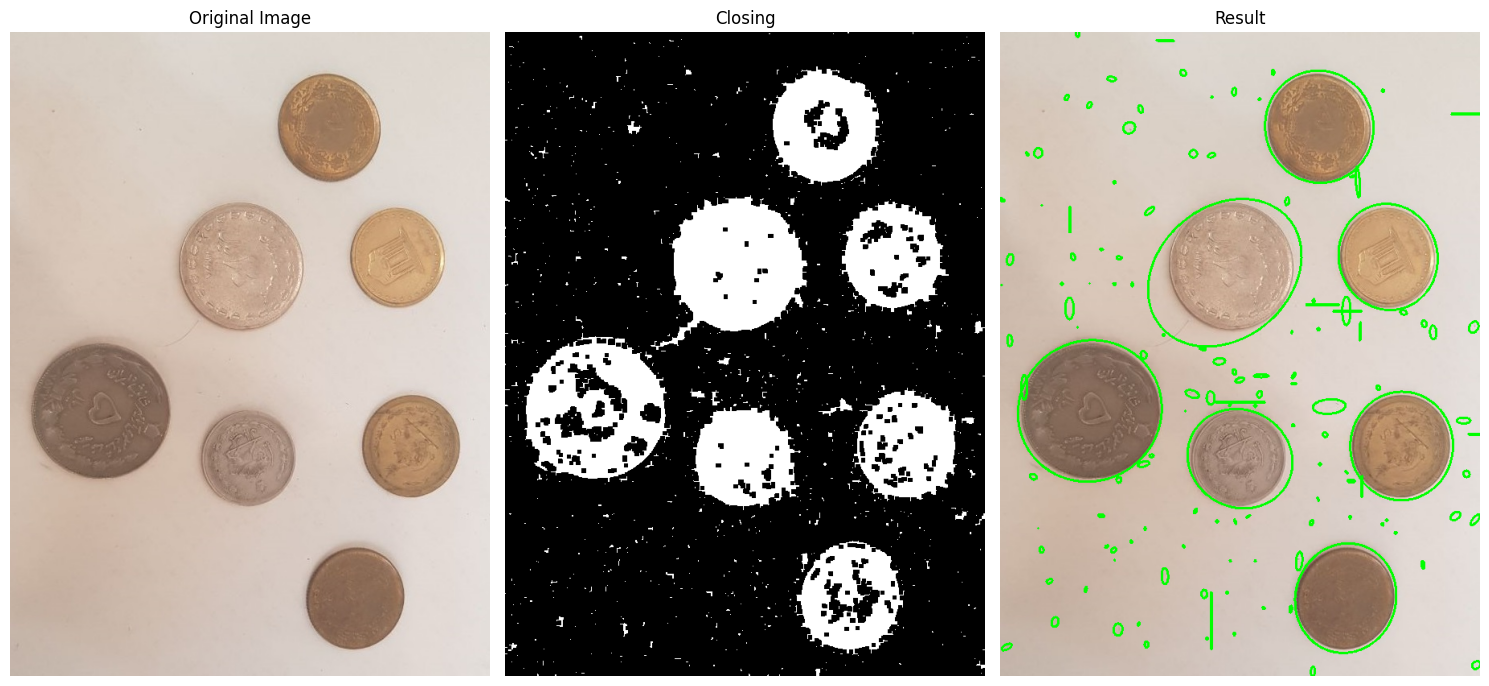

In [7]:
old_coins_image = cv2.imread(old_coins_path)
if old_coins_image is None:
  raise ValueError("Old Coins Image Not Found")

old_coins_gray = cv2.cvtColor(old_coins_image, cv2.COLOR_BGR2GRAY)

old_coins_threshold = cv2.adaptiveThreshold(
    old_coins_gray,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY_INV,
    11,
    2
)

kernel = np.ones((5, 5), np.uint8)

old_coins_closing = cv2.morphologyEx(old_coins_threshold, cv2.MORPH_CLOSE, kernel)

old_coins_contours, _ = cv2.findContours(old_coins_closing, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

first_result = old_coins_image.copy()
for contour in old_coins_contours:
  if len(contour) < 5:
    continue
  ellipse = cv2.fitEllipse(contour)
  cv2.ellipse(first_result, ellipse, (0, 255, 0), 2)

plt.figure(figsize=(15, 8))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(old_coins_image, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(old_coins_closing, cmap='gray')
plt.title('Closing')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(first_result, cv2.COLOR_BGR2RGB))
plt.title('Result')
plt.axis('off')

plt.tight_layout()
plt.show()

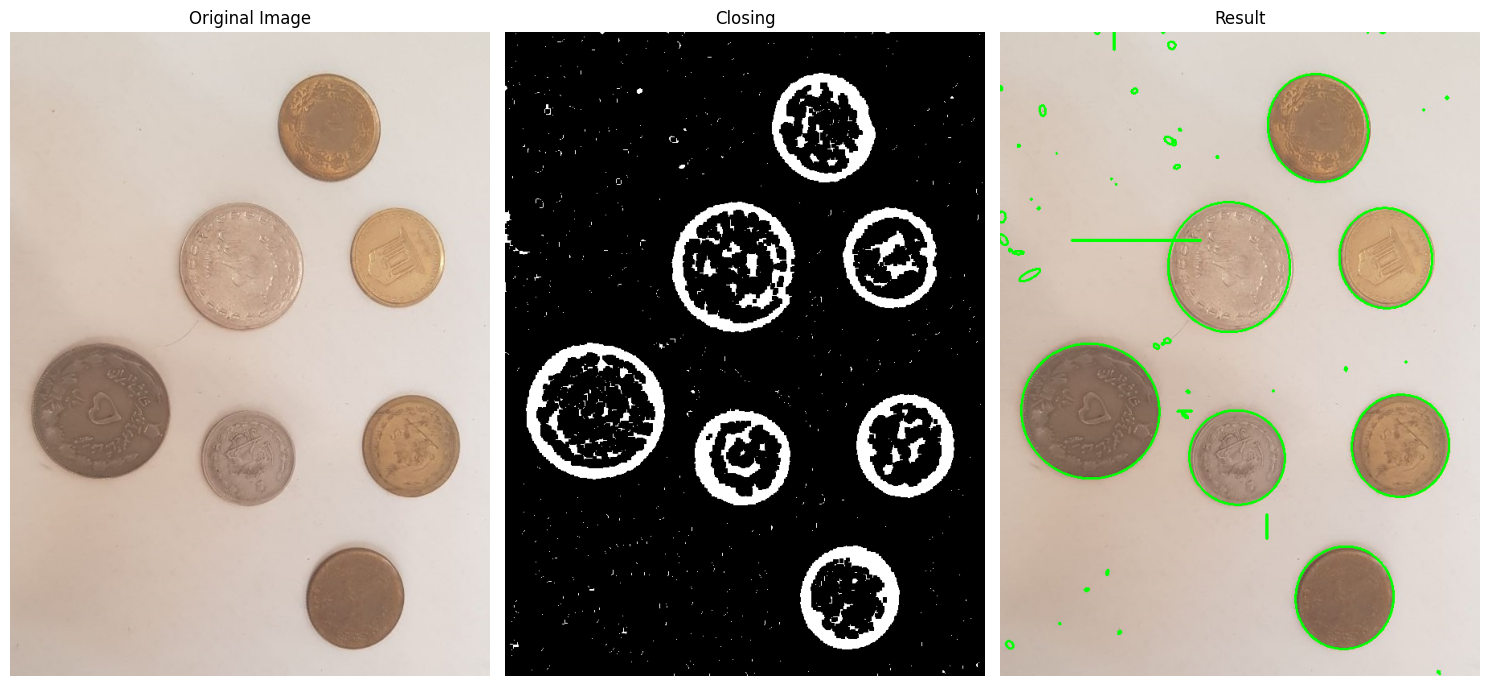

In [8]:
old_coins_blur = cv2.GaussianBlur(old_coins_gray, (31, 31), 0)

old_coins_threshold_blur = cv2.adaptiveThreshold(
    old_coins_blur,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY_INV,
    11,
    1
)

old_coins_closing_blur = cv2.morphologyEx(old_coins_threshold_blur, cv2.MORPH_CLOSE, kernel)

old_coins_contours_blur, _ = cv2.findContours(old_coins_closing_blur, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

blur_result = old_coins_image.copy()
for contour in old_coins_contours_blur:
  if len(contour) < 5:
    continue
  ellipse = cv2.fitEllipse(contour)
  cv2.ellipse(blur_result, ellipse, (0, 255, 0), 2)

plt.figure(figsize=(15, 8))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(old_coins_image, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(old_coins_closing_blur, cmap='gray')
plt.title('Closing')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(blur_result, cv2.COLOR_BGR2RGB))
plt.title('Result')
plt.axis('off')

plt.tight_layout()
plt.show()

Point Filtered Count: 7


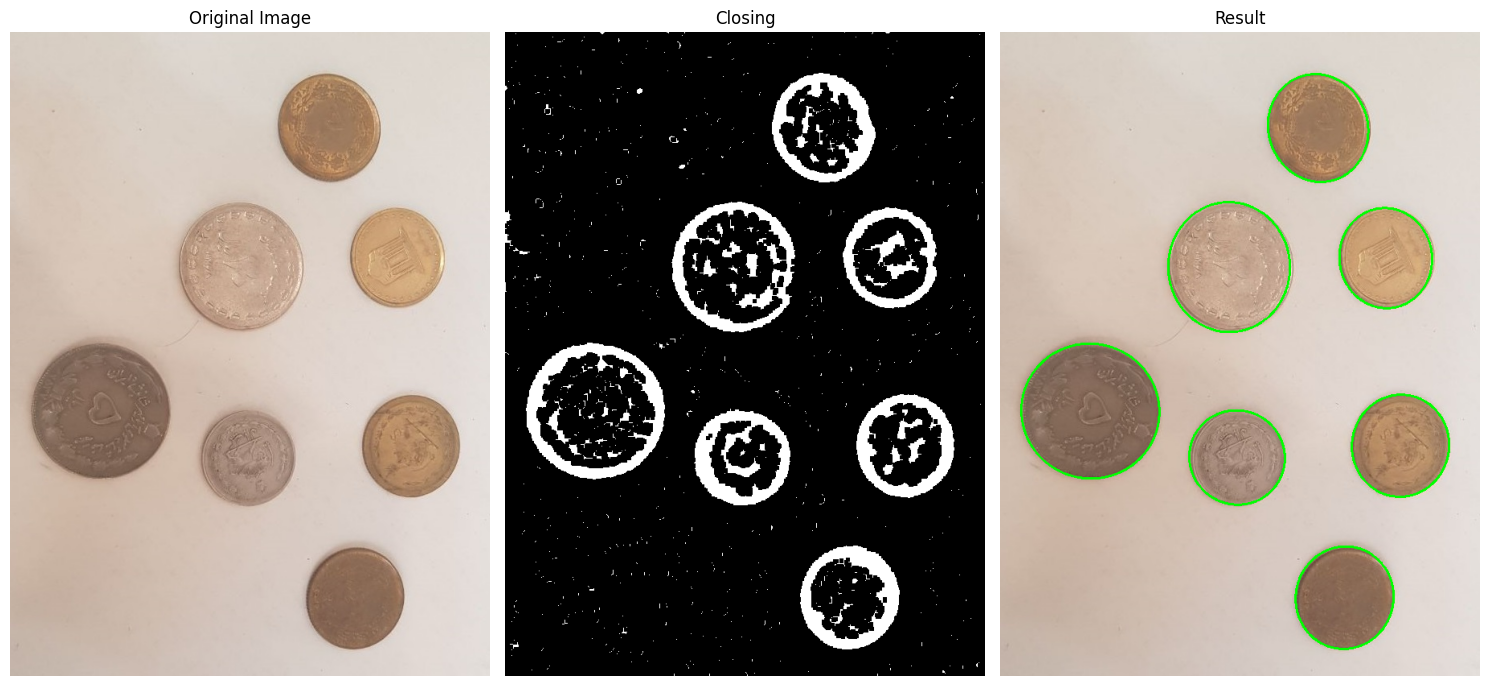

In [9]:
point_filtered_result = old_coins_image.copy()
point_filtered_count = 0

for contour in old_coins_contours_blur:
  if len(contour) < 100:
    continue

  ellipse = cv2.fitEllipse(contour)
  cv2.ellipse(point_filtered_result, ellipse, (0, 255, 0), 2)
  point_filtered_count += 1

print(f"Point Filtered Count: {point_filtered_count}")

plt.figure(figsize=(15, 8))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(old_coins_image, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(old_coins_closing_blur, cmap='gray')
plt.title('Closing')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(point_filtered_result, cv2.COLOR_BGR2RGB))
plt.title('Result')
plt.axis('off')

plt.tight_layout()
plt.show()

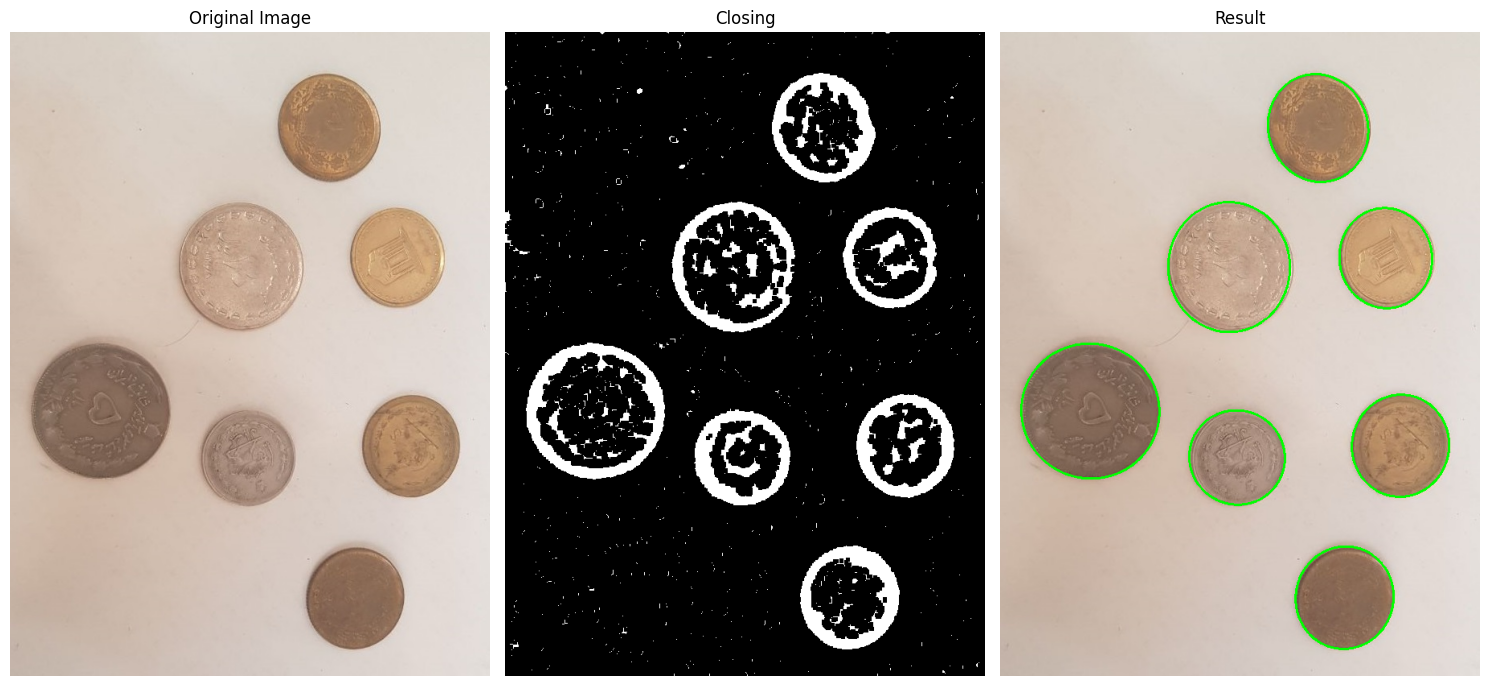

In [11]:
def detect_coins(image_path, min_area=100, max_area=50000):
  image = cv2.imread(image_path)

  if image is None:
    raise ValueError(f"Image Not Found: {image_path}")

  gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

  blur = cv2.GaussianBlur(gray, (31, 31), 0)

  threshold = cv2.adaptiveThreshold(
      blur,
      255,
      cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
      cv2.THRESH_BINARY_INV,
      11,
      1
  )

  closing = cv2.morphologyEx(threshold, cv2.MORPH_CLOSE, kernel)

  contours, _ = cv2.findContours(closing, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

  result = image.copy()
  valid_contours = []

  for contour in contours:
    area = cv2.contourArea(contour)

    if area < min_area or area > max_area:
      continue

    if len(contour) < 5:
      continue

    ellipse = cv2.fitEllipse(contour)
    cv2.ellipse(result, ellipse, (0, 255, 0), 2)
    valid_contours.append(contour)

  return result, closing, valid_contours, image

old_final, old_closing, old_valid, old_original = detect_coins(old_coins_path)

plt.figure(figsize=(15, 8))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(old_original, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(old_closing, cmap='gray')
plt.title('Closing')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(old_final, cv2.COLOR_BGR2RGB))
plt.title('Result')
plt.axis('off')

plt.tight_layout()
plt.show()

Detected Coins In Money: 14
Detected Coins In Iranian-Coin: 5


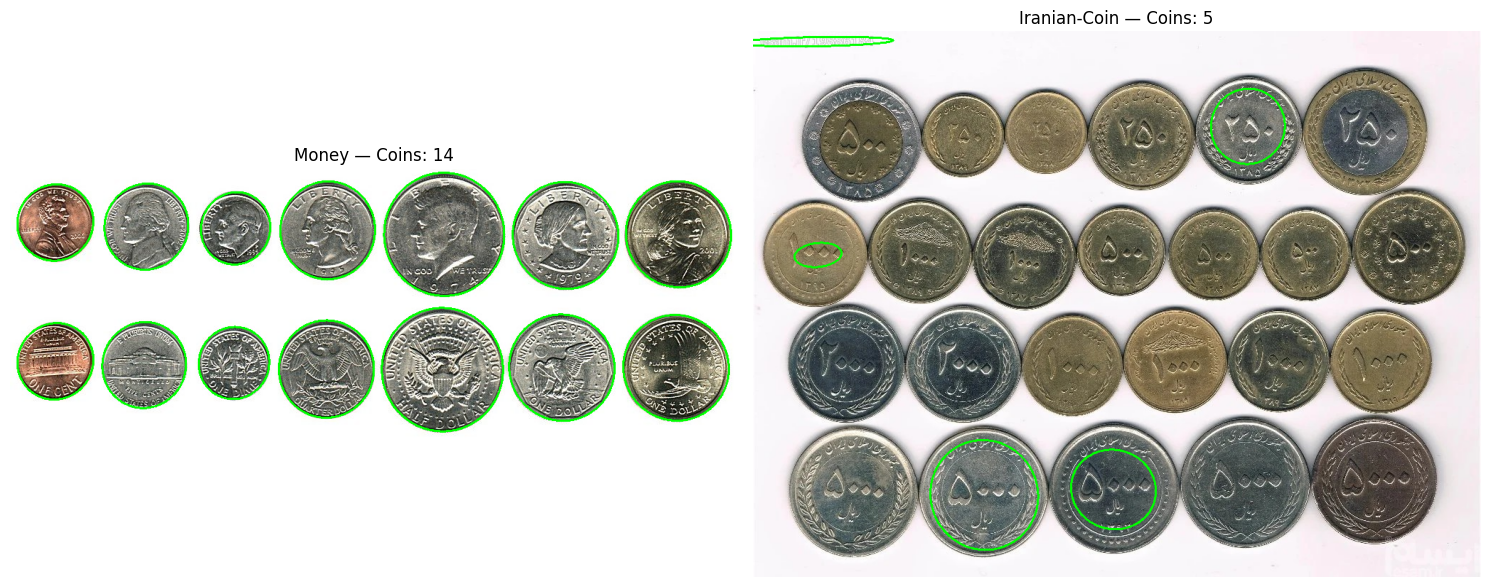

In [16]:
money_result, money_closing, money_valid, money_original = detect_coins(money_path)

iranian_result, iranian_closing, iranian_valid, iranian_original = detect_coins(iranian_coin_path)

print('Detected Coins In Money:', len(money_valid))
print('Detected Coins In Iranian-Coin:', len(iranian_valid))

plt.figure(figsize=(15, 8))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(money_result, cv2.COLOR_BGR2RGB))
plt.title(f'Money — Coins: {len(money_valid)}')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(iranian_result, cv2.COLOR_BGR2RGB))
plt.title(f'Iranian-Coin — Coins: {len(iranian_valid)}')
plt.axis('off')

plt.tight_layout()
plt.show()

In [17]:
output_images = {
    'old_iranian_coins_detected.png': old_final,
    'money_detected.png': money_result,
    'iranian_coin_detected.png': iranian_result,
}

for filename, image in output_images.items():
  output_path = '/content/' + filename
  cv2.imwrite(filename, image)
  print(f"Saved: {filename}")
  files.download(filename)
  print(f"Downloaded: {filename}")

Saved: old_iranian_coins_detected.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: old_iranian_coins_detected.png
Saved: money_detected.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: money_detected.png
Saved: iranian_coin_detected.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: iranian_coin_detected.png
